# Previsão de dengue como problema de medição

Este notebook constrói a régua da dissertação: a série-alvo, a divisão temporal que
nenhum modelo pode furar, os dois palpites ingênuos e as métricas. Ele não treina
modelo nenhum. Ele produz o número que todo modelo precisa superar.

A ordem não é preferência de estilo. Quem compara três representações de notícia
precisa saber quanto se erra **sem notícia nenhuma**, porque ganhar do nada é fácil
e não se publica. A pergunta do trabalho — a notícia acrescenta informação à série
de casos? — só tem resposta contra um erro já medido.

- **o alvo** é um só, definido em um lugar só: nenhum braço pode prever outra curva;
- **a divisão** é feita semana a semana (origem móvel), e o modelo só enxerga o
  passado até ali;
- **os ingênuos** são dois, e o que decide é o mais forte deles;
- **o resultado** são 557 semanas previstas entre 2014 e 2026, e a distância entre os
  dois ingênuos dá sentido à pergunta.

## As quatro decisões que este notebook executa

| # | Decisão | Por quê |
|---|---|---|
| 1 | Alvo é a série de casos **suspeitos**, na semana de **início de sintomas** | A notificação carrega o atraso de digitação; e a série de confirmados remove 14,6% das notificações, de forma desigual entre os anos |
| 2 | Calendário sem buraco, e falha alta quando falta uma semana | A avaliação indexa a série por posição: uma semana ausente desloca todas as seguintes e a defasagem sazonal lê a semana errada sem avisar |
| 3 | Divisão por origem móvel, com ajuste só no passado | Uma única reserva no fim deixa o modelo ser calibrado no período em que é avaliado |
| 4 | MAPE sai sempre acompanhado do seu denominador | O MAPE divide pelo valor observado: a semana pequena entra com peso grande e a semana grande com peso pequeno, o avesso do que a vigilância quer |

## Como ler as referências

Cada passo traz um bloco **Aterramento** que nomeia o artigo e o número que sustenta
a escolha. As fichas de leitura deste notebook vêm de duas famílias já montadas do
projeto — a de embeddings e a de tópicos — mais os artigos de clima e o descritor de
dados na raiz de [`articles/`](../articles/).

Um aviso que vale para o notebook inteiro: **não existe família de referências de
previsão neste projeto**. Os artigos citados foram lidos para responder a outras
perguntas, e deles se aproveita aqui só a parte que toca este problema:

- quanto atrasa a divulgação oficial;
- o que aconteceu quando alguém somou notícia a um modelo autorregressivo;
- que métrica cada um usou.

Não há, em disco, nem um manual de previsão de séries temporais nem um artigo sobre
o erro absoluto médio como métrica.
Onde a justificativa é aritmética ou é uma decisão deste protocolo, o texto diz isso
em vez de procurar um respaldo que não existe.


## O que este notebook tem que provar

1. Que o alvo tem uma definição só, que ela reproduz os totais anuais da fonte
   publicada, e que as alternativas plausíveis produziriam números diferentes.
2. Que o painel recusa uma série com buraco, e que a recusa é a diferença entre um
   erro visível e um erro silencioso.
3. Que a divisão por origem móvel não deixa nenhum modelo ler uma semana depois da
   sua origem — e que isso é verificável, não declarado.
4. Que copiar a mesma semana do ano anterior (**ingênuo sazonal**), o palpite óbvio
   para uma doença com estação marcada, é **7,6 vezes pior** que repetir a última
   semana observada.
5. Que o erro tem um lugar no calendário. Os ingênuos quebram na subida da epidemia,
   exatamente onde a notícia teria que ajudar.

O que este notebook **não** prova está na antepenúltima seção, e é longo de
propósito.

**Aterramento.** Os cinco pontos são as ablações obrigatórias de
[00-protocolo-comparacao.md](../notes/00-protocolo-comparacao.md), na parte que cabe
antes de existir um modelo. O ponto 4 tem medição publicada na direção contrária —
McGough et al. (2017),
[05_mcgough_2017_forecasting_zika_incidence_latin.pdf](../articles/topicos/05_mcgough_2017_forecasting_zika_incidence_latin.pdf),
medem zika em cinco países da América Latina e encontram que acrescentar alertas de
notícia ao modelo autorregressivo não reduziu o erro, e onde reduziu foi por menos de
2%. A hipótese de que a notícia ajuda não é óbvia nem na literatura.


## Setup

Tudo o que o notebook precisa em um lugar: caminhos, as constantes de avaliação e a
paleta dos gráficos. O notebook chama o pacote `src/forecast` em vez de reimplementar
as contas — se este notebook e o comando de linha de comando divergissem, um dos dois
estaria errado e ninguém saberia qual.

O notebook roda em dois modos. Com a tabela de casos construída, ele mede de verdade.
Sem ela, imprime o comando que a constrói e para — não há modo de fixture aqui, e a
diferença em relação aos notebooks dos braços é deliberada: um número de erro
calculado sobre texto sintético seria um número sem significado, e um notebook que
imprime uma tabela nessas condições convida a citá-la.


In [1]:
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# A raiz do projeto entra no path, e não `src/`, como fazem os notebooks dos braços.
# O motivo é que `forecast` é irmão de `pipeline` e importa dele: com `src/` no path,
# `forecast` vira pacote de topo, `pipeline` vira outro, e o import relativo entre os
# dois deixa de ter ancestral comum. Com a raiz no path existe um pacote `src` só, e
# `forecast` e `pipeline` são os dois subpacotes dele — a mesma raiz que o
# `pyproject.toml` declara no entry point `src.collection.cli:main`.
sys.path.insert(0, str(PROJECT_ROOT))

from src.forecast.baselines import persistence, seasonal_naive
from src.forecast.evaluate import evaluate
from src.forecast.metrics import mae, mape, mape_denominator, rmse
from src.forecast.panel import TargetGapError, load_target
from src.forecast.spec import (
    CASES, DEFAULT_HORIZON, DEFAULT_MIN_TRAIN, EW, FIRST_COMPLETE_YEAR, SEASONAL_LAG,
)
from src.forecast.splits import rolling_origin
from src.pipeline.sinan.spec import EW_SYMPTOM_ONSET

pl.Config.set_tbl_rows(20)
pl.Config.set_fmt_str_lengths(60)

# --- caminhos ---------------------------------------------------------------
SINAN_PATH = PROJECT_ROOT / "data" / "epidemiological" / "SINAN" / "SINAN_dengue_cases.parquet"

REAL = SINAN_PATH.exists()
print("tabela de casos do SINAN:", "presente" if REAL else "AUSENTE")
if not REAL:
    print()
    print("Rode primeiro, a partir da raiz do repositório:")
    print("    uv run arboili transform sinan     # ~11 s sobre os CSVs anuais")
    print()
    print("O notebook para aqui: sem a tabela não há alvo, e sem alvo não há erro.")


tabela de casos do SINAN: presente


### A paleta dos gráficos

Os gráficos usam a mesma paleta categórica de ordem fixa dos outros notebooks do
projeto. A ordem não é estética: os pares de cores adjacentes foram medidos para
separação sob daltonismo (deuteranopia, protanopia, tritanopia), e só ordens que
passam em todos os pares foram mantidas. Três cores é o teto para séries visíveis ao
mesmo tempo; a magnitude usa uma rampa de uma cor só, e o texto usa tinta neutra, nunca
a cor da série.


In [2]:
PALETTE = {
    "surface": "#fcfcfb",
    "ink": "#0b0b0b",
    "ink2": "#52514e",
    "muted": "#898781",
    "grid": "#e1e0d9",
    "axis": "#c3c2b7",
    # Os três primeiros passos, na ordem validada. Não ciclar, não reordenar.
    "series": ("#2a78d6", "#eb6834", "#1baf7a"),
    "seq": ("#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"),
    "critical": "#d03b3b",
    "good": "#0ca30c",
}


def style_axes(ax, title=None, xlabel=None, ylabel=None):
    """Aparência comum: grade recessiva, eixos finos, tinta neutra."""
    ax.set_facecolor(PALETTE["surface"])
    ax.grid(True, color=PALETTE["grid"], linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(PALETTE["axis"])
        ax.spines[side].set_linewidth(1.0)
    ax.tick_params(colors=PALETTE["muted"], labelsize=9, length=0)
    for label, text in (("title", title), ("xlabel", xlabel), ("ylabel", ylabel)):
        if text:
            getattr(ax, f"set_{label}")(text, color=PALETTE["ink2"], fontsize=11)
    return ax


print("paleta carregada — 3 séries categóricas validadas para daltonismo")


paleta carregada — 3 séries categóricas validadas para daltonismo


## 1. Por que os ingênuos vêm primeiro

Uma representação de notícia que não vence uma reta traçada sobre a própria série de
casos não é um achado sobre a notícia: é um achado sobre o modelo que a consumiu. Por
isso a comparação começa por dois palpites que não usam texto nenhum, e por isso os
dois são medidos antes de existir um só modelo treinado.

A literatura levantada sustenta essa ordem de dois jeitos incômodos. Gautam et al.
(2025),
[17_gautam_2025_attention_news_outbreak.pdf](../articles/embeddings/17_gautam_2025_attention_news_outbreak.pdf),
montam um preditor de surto a partir de notícia e registram que **não existe benchmark
público** para essa tarefa, de modo que os números deles servem como linha de base
preliminar. Sem régua externa, a régua tem que ser construída aqui. McGough et al.
(2017) medem o caso mais próximo deste trabalho e encontram o efeito quase nulo: em
cinco países, somar alertas de notícia a um modelo que já usava busca do Google não
reduziu o erro de previsão em nenhum horizonte, e a redução que apareceu em El Salvador
ficou abaixo de 2%.

Nenhum dos dois é razão para não fazer a comparação. Os dois são razão para medir a
régua antes de usá-la.

**Aterramento.** O ponto 1 é a lacuna que Gautam et al. (2025) declaram na discussão
do próprio artigo, e é a justificativa prática do baseline local. Os dois ingênuos
escolhidos são os que a estrutura da série impõe: dengue tem inércia de uma semana e
sazonalidade anual, então os dois palpites a testar são repetir a última semana e
repetir a mesma semana do ano anterior. O protocolo 00 fixa essa ordem em
§Ablações obrigatórias.


## 2. O alvo, e por que cada palavra dele muda o número

O alvo é a série de casos **suspeitos** de dengue por semana epidemiológica de
**início de sintomas**, no Brasil. As três escolhas carregam consequência.

**Sintoma, e não notificação.** A semana da notificação carrega o atraso de digitação
do sistema, que varia por estado e por época do ano. Duas séries ancoradas em datas
diferentes não são comparáveis, e o protocolo 00 fixa o início de sintomas para todos
os braços.

**Suspeitos, e não confirmados.** Suspeito é toda notificação menos as descartadas
depois de investigação. A série de confirmados remove as notificações que ainda não
terminaram de ser investigadas, o que no período significa 2,8 milhões de registros,
14,6% do total — e remove de forma desigual: 31% da série de 2017 contra 8% da de
2024. Um modelo treinado nessa curva aprende a prever uma curva que a vigilância não
publica.

**Uma definição, e não três.** Ela é a da implementação publicada e reproduz os totais
anuais do descritor de dados, ano a ano, de 2014 a 2023. Ela mora em um módulo só
porque antes não morava: três notebooks deste projeto somavam a série de três jeitos,
e as três séries diferiam em até 42% do total. Essa diferença é maior que qualquer
efeito que a notícia possa ter, e era invisível enquanto ninguém tinha posto as três
lado a lado.

**Aterramento.** A definição e os totais anuais são de Borges et al. (2026),
[00_borges_2026_arboili_data_descriptor.pdf](../articles/00_borges_2026_arboili_data_descriptor.pdf),
o descritor de dados do conjunto que este repositório reproduz. A partição entre
sintoma e notificação, e o número de 42%, estão medidos em
[`src/pipeline/sinan/cases.py`](../src/pipeline/sinan/cases.py), que é o único lugar
onde a definição existe.


In [3]:
if REAL:
    panel = load_target(str(SINAN_PATH), from_year=FIRST_COMPLETE_YEAR)
    print(f"semanas: {panel.height}")
    print(f"janela:  {panel[EW].min()} → {panel[EW].max()}")
    print(f"casos:   {panel[CASES].sum():,}")
    print(f"mínimo semanal: {panel[CASES].min():,} casos — a série nunca chega a zero")


semanas: 661
janela:  2014-01-05 → 2026-08-30
casos:   19,039,254
mínimo semanal: 1,341 casos — a série nunca chega a zero


### A série, desenhada

Vale olhar antes de medir. O que a figura mostra decide o que se pode esperar de
qualquer modelo: uma sazonalidade anual reconhecível, um vale profundo entre
epidemias, e um pico que não se parece com os outros.


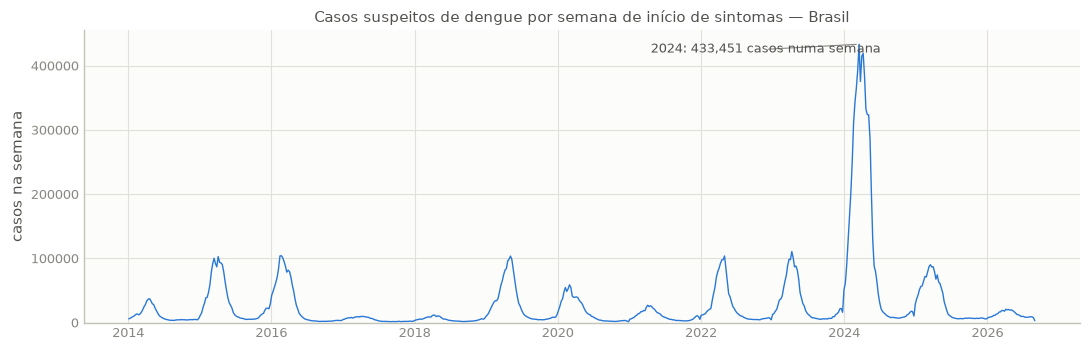

In [4]:
if REAL:
    fig, ax = plt.subplots(figsize=(11, 3.6))
    ax.plot(panel[EW].to_list(), panel[CASES].to_list(),
            color=PALETTE["series"][0], linewidth=1.0)
    peak = panel.sort(CASES, descending=True).row(0, named=True)
    ax.annotate(
        f"{peak[EW].year}: {peak[CASES]:,} casos numa semana",
        xy=(peak[EW], peak[CASES]),
        xytext=(-150, -6), textcoords="offset points",
        color=PALETTE["ink2"], fontsize=9,
        arrowprops=dict(arrowstyle="-", color=PALETTE["muted"], linewidth=0.8),
    )
    style_axes(
        ax,
        title="Casos suspeitos de dengue por semana de início de sintomas — Brasil",
        ylabel="casos na semana",
    )
    ax.set_ylim(bottom=0)
    plt.tight_layout()
    plt.show()


O pico de 2024 é o fato que organiza a avaliação inteira. Nenhum outro ano do período
se aproxima dele, e um modelo que aprendeu com 2015 a 2023 não tem de onde tirar
aquela magnitude. Guarde esse número: ele reaparece na seção 8 como a razão de o
ingênuo sazonal falhar tão alto.


## 3. Por que o painel começa em 2014, e não em 2013

O arquivo do SINAN tem semanas de 2013. Elas não servem. O que existe daquele ano é a
cauda de início de sintomas das notificações feitas em 2014, e três semanas ficaram
sem nenhum registro.

Uma semana ausente não é um dado faltante a preencher. A avaliação indexa a série por
posição: a previsão do passo *i* é comparada com o valor na posição *i*. Tirando uma
semana do meio, toda posição depois dela anda uma casa, e a defasagem sazonal de 52
passa a ler a 51ª ou a 53ª semana — sem erro, sem aviso, e com o número final
levemente errado de um jeito que ninguém consegue rastrear depois.

O painel resolve isso reconstruindo o calendário e recusando a série quando encontra
um buraco. Vamos ver a recusa acontecer.


In [5]:
if REAL:
    raw = pl.read_parquet(SINAN_PATH)
    holed = raw.filter(pl.col(EW_SYMPTOM_ONSET) != pl.date(2020, 6, 7))

    with tempfile.TemporaryDirectory() as tmp:
        path = Path(tmp) / "com_buraco.parquet"
        holed.write_parquet(path)
        try:
            load_target(str(path), from_year=2014)
            print("o painel aceitou a série com buraco — isso seria o defeito")
        except TargetGapError as exc:
            print("TargetGapError, como esperado:\n")
            print(str(exc))


TargetGapError, como esperado:

1 week(s) missing from the target series between 2014-01-05 and 2026-08-30: 2020-06-07. A gap shifts every later position, so the seasonal lag would read the wrong week without raising. Narrow the window with `from_year` to a period that is complete.


### O que o deslocamento faria com a defasagem, medido

A recusa é uma afirmação sobre aritmética, e aritmética se demonstra. Abaixo, a mesma
pergunta — qual semana do ano anterior esta semana copia? — respondida das duas
maneiras.


In [6]:
if REAL:
    semanas = panel[EW].to_list()
    i = len(semanas) - 1
    ano_antes = semanas[i].replace(year=semanas[i].year - 1)

    print(f"a semana que está sendo prevista:           {semanas[i]}")
    print(f"o mesmo ponto do calendário, um ano antes:  {ano_antes}")
    print(f"o que a posição i-52 aponta no painel:      {semanas[i - SEASONAL_LAG]}")
    print()

    desvios: dict[int, int] = {}
    for k in range(SEASONAL_LAG, len(semanas)):
        try:
            mesmo_dia = semanas[k].replace(year=semanas[k].year - 1)
        except ValueError:  # 29 de fevereiro num ano não bissexto
            mesmo_dia = semanas[k].replace(year=semanas[k].year - 1, day=28)
        atraso = (semanas[k - SEASONAL_LAG] - mesmo_dia).days
        desvios[atraso] = desvios.get(atraso, 0) + 1

    print("quanto a posição i-52 erra o mesmo ponto do calendário:")
    for dias, n in sorted(desvios.items()):
        print(f"   {dias} dia(s) à frente — {n} semanas do painel")


a semana que está sendo prevista:           2026-08-30
o mesmo ponto do calendário, um ano antes:  2025-08-30
o que a posição i-52 aponta no painel:      2025-08-31

quanto a posição i-52 erra o mesmo ponto do calendário:
   1 dia(s) à frente — 452 semanas do painel
   2 dia(s) à frente — 157 semanas do painel


Três fatos saem daí, e os três importam.

O primeiro: a posição 52 atrás **nunca é o mesmo dia do calendário**. Cinquenta e
duas semanas são 364 dias, e um ano tem 365 ou 366, então a defasagem lê um dia à
frente em 452 semanas do painel e dois dias em 157. Ela caminha sozinha, cerca de um
dia por ciclo.

O segundo: o painel sem buraco é o que permite afirmar isso. O desvio medido é do
calendário, e não de uma semana que faltou — se o painel tivesse um buraco, esse mesmo
cálculo daria um número parecido e não haveria como separar as duas causas.

O terceiro: um dia é aceitável nesta série e uma semana não é. A temporada de dengue
muda de patamar em poucas semanas, e é por isso que o painel recusa a série com buraco
em vez de preencher a semana ausente com uma média.


## 4. A divisão: uma reserva no fim não serve

Separar treino e teste uma vez, no fim da série, é o desenho mais comum e o pior para
esta pergunta. Ele deixa duas portas abertas.

A primeira é a calibração: com uma reserva única, tudo o que for escolhido — o número
de componentes, a janela de ajuste, o limiar — pode ser escolhido olhando o resultado
naquele período. O modelo passa a ser avaliado no conjunto em que foi ajustado, e o
número que sai é otimista de um jeito que não dá para quantificar depois.

A segunda é a estabilidade. Um método que funciona em 2021 e desanda em 2024 recebe,
com reserva única, uma média só e nenhum aviso. A média esconde exatamente o que
interessa.

A divisão por origem móvel resolve as duas. O modelo é reajustado a cada semana, com
o que existia até ali, e prevê a semana seguinte. A regra que a implementação garante
é curta: **na origem *i*, o modelo lê a série até a posição *i* e nada depois dela.**


In [7]:
if REAL:
    origens = list(rolling_origin(panel, min_train=DEFAULT_MIN_TRAIN, horizon=DEFAULT_HORIZON))

    print(f"semanas no painel:        {panel.height}")
    print(f"semanas de histórico:     {DEFAULT_MIN_TRAIN} (duas temporadas)")
    print(f"horizonte:                {DEFAULT_HORIZON} semana")
    print(f"origens avaliadas:        {len(origens)}")
    print(f"primeira origem:          {origens[0].ew}  → prevê {panel[EW][origens[0].index + 1]}")
    print(f"última origem:            {origens[-1].ew}  → prevê {panel[EW][origens[-1].index + 1]}")
    print()
    print("o histórico entregue ao modelo, na primeira origem, termina em:")
    print(f"  {panel[EW][origens[0].train_end - 1]}  (a própria semana da origem)")


semanas no painel:        661
semanas de histórico:     104 (duas temporadas)
horizonte:                1 semana
origens avaliadas:        557
primeira origem:          2015-12-27  → prevê 2016-01-03
última origem:            2026-08-23  → prevê 2026-08-30

o histórico entregue ao modelo, na primeira origem, termina em:
  2015-12-27  (a própria semana da origem)


### A regra do vazamento, conferida em vez de prometida

Um notebook afirma que nenhum modelo vê o futuro. Isso é fácil de escrever e fácil de
errar, então vale um teste que falharia se a afirmação fosse falsa: dois painéis
idênticos até certa semana e radicalmente diferentes depois dela. Se alguma previsão
feita **antes** do ponto de divergência mudar entre os dois, alguma coisa leu o futuro.


In [8]:
if REAL:
    corte = panel[EW][300]
    calmo = panel.with_columns(
        pl.when(pl.col(EW) > corte).then(pl.lit(1.0)).otherwise(pl.col(CASES)).alias(CASES)
    )
    choque = panel.with_columns(
        pl.when(pl.col(EW) > corte).then(pl.lit(999_999.0)).otherwise(pl.col(CASES)).alias(CASES)
    )

    def previsoes_ate(frame: pl.DataFrame) -> pl.DataFrame:
        run = evaluate(frame, baselines=("persistence",),
                       min_train=DEFAULT_MIN_TRAIN, horizon=DEFAULT_HORIZON)
        # Estritamente antes do corte: uma origem no próprio corte prevê a semana
        # seguinte, que já está no mundo divergente.
        return run.predictions.filter(pl.col("origin_ew") < corte)

    a, b = previsoes_ate(calmo), previsoes_ate(choque)
    print(f"origens antes do corte:              {a.height}")
    print(f"previsões idênticas nos dois mundos: {a.equals(b)}")
    print()
    print("o mundo 'choque' multiplicou por mil tudo depois do corte.")
    print("Nenhuma previsão anterior a ele se moveu — a origem móvel está contida.")


origens antes do corte:              197
previsões idênticas nos dois mundos: True

o mundo 'choque' multiplicou por mil tudo depois do corte.
Nenhuma previsão anterior a ele se moveu — a origem móvel está contida.


## 5. Os dois palpites

**O primeiro é repetir a última semana observada (persistência).** É o palpite de quem
aposta na inércia, e numa série com correlação de uma semana para a outra ele é duro de
bater.

**O segundo é copiar a mesma semana do ano anterior (ingênuo sazonal).** É o palpite
de quem aposta na sazonalidade, que é o palpite que qualquer pessoa informada daria
sobre uma doença sazonal.

Nenhum dos dois é ajustado, então os dois são exatamente reprodutíveis e nenhum pode
vazar: não há o que treinar sobre o futuro.

Um detalhe que não é detalhe: com horizonte maior que uma semana, o ingênuo sazonal
**caminha** pela estação anterior em vez de repetir um valor. Repetir faria o quarto
passo ser uma cópia do primeiro, e a linha de base ficaria artificialmente boa nos
horizontes longos.


In [9]:
historico = [10.0, 20.0, 30.0, 40.0, 50.0, 60.0]
print("histórico inventado:", historico)
print()
print("persistência, 4 semanas à frente:    ", persistence(historico, horizon=4))
print("ingênuo sazonal (lag 4), 4 semanas:  ", seasonal_naive(historico, horizon=4, lag=4))
print()
print("o sazonal não repete 60 quatro vezes: ele lê as quatro semanas da")
print("estação anterior, na ordem em que elas vão acontecer.")
print()
print("e um horizonte maior que o lag é recusado, porque a estação anterior")
print("já teria entrado nas semanas observadas:")
try:
    seasonal_naive(historico, horizon=7, lag=4)
except ValueError as exc:
    print(f"  ValueError: {exc}")


histórico inventado: [10.0, 20.0, 30.0, 40.0, 50.0, 60.0]

persistência, 4 semanas à frente:     [60.0, 60.0, 60.0, 60.0]
ingênuo sazonal (lag 4), 4 semanas:   [30.0, 40.0, 50.0, 60.0]

o sazonal não repete 60 quatro vezes: ele lê as quatro semanas da
estação anterior, na ordem em que elas vão acontecer.

e um horizonte maior que o lag é recusado, porque a estação anterior
já teria entrado nas semanas observadas:
  ValueError: horizon 7 exceeds lag 4: past 4 steps the previous season runs into the observed weeks, and the baseline would be copying the present instead of forecasting.


### Os dois palpites, numa origem real

Antes de agregar em métrica, vale ver o que cada um responde numa semana concreta.


In [10]:
if REAL:
    origem = origens[-2]
    valores = panel[CASES].to_list()
    hist = [float(v) for v in valores[: origem.train_end]]
    alvo = panel[EW][origem.index + 1]
    observado = valores[origem.index + 1]

    print(f"origem: {origem.ew}   |   semana prevista: {alvo}")
    print()
    print(f"  observado:            {observado:>9,.0f}")
    print(f"  persistência:         {persistence(hist, 1)[0]:>9,.0f}")
    print(f"  ingênuo sazonal:      {seasonal_naive(hist, 1)[0]:>9,.0f}")
    print()
    print("o ingênuo sazonal copiou a semana equivalente de um ano antes —")
    print("e a diferença entre os dois palpites é o que a seção 7 vai medir.")


origem: 2026-08-16   |   semana prevista: 2026-08-23

  observado:                7,977
  persistência:             8,936
  ingênuo sazonal:          6,053

o ingênuo sazonal copiou a semana equivalente de um ano antes —
e a diferença entre os dois palpites é o que a seção 7 vai medir.


## 6. As métricas, e a armadilha de uma delas

Três métricas pontuais, todas em casos por semana.

**Erro absoluto médio (MAE)** é o número principal. É a média da distância entre o
previsto e o observado, na unidade da série, e é o único dos três que se lê sem
tradução: "errou 4.047 casos por semana" quer dizer o que diz.

**Raiz do erro quadrático médio (RMSE)** acompanha o MAE e nunca o substitui. A
distância entre os dois descreve a forma do erro: uma raiz muito acima da média significa
que poucas semanas concentram o erro, o que nesta série é a assinatura de um pico de
epidemia perdido.

**Erro percentual absoluto médio (MAPE)** é o mais citado e o que mais engana. Ele
divide o erro pelo valor observado, o que parece razoável e inverte a prioridade: a
semana pequena entra com peso grande e a semana grande entra com peso pequeno. Numa
métrica de vigilância isso é o avesso do que se quer — uma epidemia errada por 84 mil
casos importa mais que um vale errado por mil.

O efeito é fácil de ver com dois números.


In [11]:
# Duas semanas reais em escala: 1.341 é o menor valor da série, 200.000 um pico
# de epidemia. O mesmo erro absoluto nas duas — 1.070 casos.
observado = [1_341.0, 200_000.0]
previsto = [2_411.0, 201_070.0]

erro_pequena = abs(previsto[0] - observado[0])
erro_grande = abs(previsto[1] - observado[1])

print(f"erro absoluto na semana pequena: {erro_pequena:>8,.0f} casos "
      f"({erro_pequena / observado[0] * 100:>5.1f}% do observado)")
print(f"erro absoluto na semana grande:  {erro_grande:>8,.0f} casos "
      f"({erro_grande / observado[1] * 100:>5.1f}% do observado)")
print()
print(f"o MAE das duas semanas: {mae(observado, previsto):>8,.0f} casos")
print(f"o MAPE das duas semanas: {mape(observado, previsto) * 100:>7.1f}%")
print()
print("O erro é idêntico. O MAPE trata a semana pequena como se ela fosse")
print("quase 150 vezes pior, e é essa a ponderação que ele aplica em toda a média.")


erro absoluto na semana pequena:    1,070 casos ( 79.8% do observado)
erro absoluto na semana grande:     1,070 casos (  0.5% do observado)

o MAE das duas semanas:    1,070 casos
o MAPE das duas semanas:    40.2%

O erro é idêntico. O MAPE trata a semana pequena como se ela fosse
quase 150 vezes pior, e é essa a ponderação que ele aplica em toda a média.


Duas defesas, e as duas estão no código em vez de no texto.

A primeira é o denominador. O MAPE é indefinido onde o observado é zero, e o código
descarta essas semanas **e informa quantas descartou**, porque um MAPE citado sem essa
contagem é um número cuja base ninguém conhece. Nesta série nada é descartado — o piso
é 1.341 casos — mas o campo existe para que a série não precise ser esta.

A segunda é não andar sozinho. O MAPE entra na tabela ao lado das outras duas, e a
seção 7 mostra o preço de confiar só nele: as três métricas discordam sobre qual foi a
pior semana.


## 7. O primeiro número

Agora a medição. Brasil inteiro, uma semana à frente, 104 semanas de histórico antes
da primeira previsão, e uma previsão por semana até o fim da série.


In [12]:
if REAL:
    run = evaluate(
        panel,
        horizon=DEFAULT_HORIZON,
        min_train=DEFAULT_MIN_TRAIN,
    )
    print(run.summary())
    print()
    print(f"previsões avaliadas: {run.predictions.height:,} "
          f"({run.horizon} por origem × {len(origens)} origens × {len(run.baselines)} palpites)")


      baseline  step  weeks     MAE    RMSE    MAPE  MAPE n
--------------  ----  -----  ------  ------  ------  ------
   persistence     1    557   4,047   9,716   13.3%     557
seasonal_naive     1    557  30,714  70,080  119.8%     557

previsões avaliadas: 1,114 (1 por origem × 557 origens × 2 palpites)


In [13]:
if REAL:
    # `display` e não a expressão solta: dentro de um `if`, a última expressão da
    # célula não vira saída, e a tabela sairia em branco sem avisar.
    display(run.metrics.select(
        pl.col("baseline"),
        pl.col("n").alias("semanas"),
        pl.col("mean_truth").round(0).alias("média observada"),
        pl.col("mae").round(0).alias("MAE"),
        pl.col("rmse").round(0).alias("RMSE"),
        (pl.col("mape") * 100).round(1).alias("MAPE %"),
        pl.col("mape_n").alias("semanas no MAPE"),
    ))


baseline,semanas,média observada,MAE,RMSE,MAPE %,semanas no MAPE
str,i64,f64,f64,f64,f64,i64
"""persistence""",557,30046.0,4047.0,9716.0,13.3,557
"""seasonal_naive""",557,30046.0,30714.0,70080.0,119.8,557


### As três métricas discordam sobre a pior semana

A ponderação da seção 6 não é hipótese. Ela está no resultado desta execução, e o jeito
de vê-la é perguntar a cada métrica qual foi a pior semana.


In [14]:
if REAL:
    f = run.predictions.filter(pl.col("baseline") == "persistence").with_columns(
        (pl.col("y_true") - pl.col("y_pred")).abs().alias("erro"),
        ((pl.col("y_true") - pl.col("y_pred")).abs() / pl.col("y_true")).alias("pct"),
    )
    pior_mae = f.sort("erro", descending=True).row(0, named=True)
    pior_mape = f.sort("pct", descending=True).row(0, named=True)

    print(f"  {'métrica':<9} {'semana':<12} {'observado':>10} {'previsto':>10} "
          f"{'erro':>9} {'erro %':>8}")
    for metrica, r in (("MAE", pior_mae), ("MAPE", pior_mape)):
        print(f"  {metrica:<9} {str(r['ew']):<12} {r['y_true']:>10,.0f} "
              f"{r['y_pred']:>10,.0f} {r['erro']:>9,.0f} {r['pct'] * 100:>7,.0f}%")
    print()
    print(f"a semana que o MAE chama de pior errou {pior_mae['erro'] / pior_mape['erro']:.0f} "
          f"vezes mais casos que a que o MAPE chama de pior,")
    print(f"e o MAPE dela é {pior_mape['pct'] / pior_mae['pct']:.1f} vezes menor.")
    print()
    print("a pior semana do MAPE é a última do painel — a que está incompleta")
    print("por atraso de notificação, com 3.330 casos contra ~9.000 nas anteriores.")
    print("É um artefato do sistema de notificação, não uma semana de baixa real.")
    print()
    print(f"semanas que o MAPE conseguiu pontuar: "
          f"{mape_denominator(f['y_true'].to_list())} de {f.height}")


  métrica   semana        observado   previsto      erro   erro %
  MAE       2024-05-19      201,003    285,742    84,739      42%
  MAPE      2026-08-30        3,330      7,977     4,647     140%

a semana que o MAE chama de pior errou 18 vezes mais casos que a que o MAPE chama de pior,
e o MAPE dela é 3.3 vezes menor.

a pior semana do MAPE é a última do painel — a que está incompleta
por atraso de notificação, com 3.330 casos contra ~9.000 nas anteriores.
É um artefato do sistema de notificação, não uma semana de baixa real.

semanas que o MAPE conseguiu pontuar: 557 de 557


A semana que o MAE chama de pior é a de 19 de maio de 2024, com 201.003 casos
observados e 285.742 previstos: o auge da epidemia recorde, errado por 84.739 casos. A
semana que o MAPE chama de pior é a última do painel, errada por 4.647 casos — dezoito
vezes menos — e que só aparece no topo porque é pequena.

A escolha entre as duas não é técnica, é sobre o que a dissertação quer dizer. Se o que
importa é quantos casos o sistema deixou de prever, a resposta é o MAE e é maio de 2024.
Se o que importa é o erro relativo, a resposta é a última semana, que nem é um problema
de previsão. Reportar as três e dizer a discordância é o que o protocolo 00 pede.


### A distância entre os dois, e por que ela é o ponto

A persistência erra **4.047 casos por semana**. O ingênuo sazonal erra **30.714** —
7,6 vezes mais. O palpite que qualquer pessoa informada daria sobre uma doença sazonal
é o pior dos dois, e com folga.

A razão está na figura da seção 2. O ingênuo sazonal copia o nível do ano anterior, e
esta série não repete nível: 2024 teve média de 125.779 casos por semana contra 32.001
em 2023. Copiar 2023 dentro de 2024 erra por um fator de quatro na direção oposta ao
que se quer — o método é pior justamente no ano que mais importa.

Isso tem uma consequência prática para a dissertação. "O modelo bate a linha de base
ingênua" é uma frase que não significa nada sem dizer **qual** ingênua, e o ingênuo
honesto aqui é a persistência. Comparar contra o sazonal seria escolher o adversário
mais fraco e chamar a vitória de achado.


In [15]:
if REAL:
    p = run.metrics.filter(pl.col("baseline") == "persistence").row(0, named=True)
    s = run.metrics.filter(pl.col("baseline") == "seasonal_naive").row(0, named=True)

    print(f"razão entre os dois erros: {s['mae'] / p['mae']:.1f}×")
    print()
    print("e o RMSE conta a mesma história com mais força:")
    print(f"  persistência   MAE {p['mae']:>9,.0f}   RMSE {p['rmse']:>9,.0f}"
          f"   (RMSE/MAE = {p['rmse'] / p['mae']:.1f})")
    print(f"  sazonal        MAE {s['mae']:>9,.0f}   RMSE {s['rmse']:>9,.0f}"
          f"   (RMSE/MAE = {s['rmse'] / s['mae']:.1f})")
    print()
    print("a razão RMSE/MAE mede quanto o erro se concentra em poucas semanas.")
    print("A persistência concentra menos: o erro dela é mais espalhado e mais honesto.")


razão entre os dois erros: 7.6×

e o RMSE conta a mesma história com mais força:
  persistência   MAE     4,047   RMSE     9,716   (RMSE/MAE = 2.4)
  sazonal        MAE    30,714   RMSE    70,080   (RMSE/MAE = 2.3)

a razão RMSE/MAE mede quanto o erro se concentra em poucas semanas.
A persistência concentra menos: o erro dela é mais espalhado e mais honesto.


## 8. O número é robusto, e o erro tem endereço

Antes de aceitar 4.047 como régua, vale tentar derrubá-lo. Há duas maneiras óbvias de
suspeitar do resultado, e as duas se testam.


In [16]:
if REAL:
    def erro(frame: pl.DataFrame) -> float:
        return frame.select((pl.col("y_true") - pl.col("y_pred")).abs()).to_series().mean()

    for nome in run.baselines:
        f = run.predictions.filter(pl.col("baseline") == nome)
        sem_2024 = f.filter(pl.col("ew").dt.year() != 2024)
        sem_ultima = f.filter(pl.col("ew") < f["ew"].max())
        print(f"{nome}:")
        print(f"    tudo                        {erro(f):>9,.0f}")
        print(f"    sem o ano epidêmico de 2024 {erro(sem_2024):>9,.0f}")
        print(f"    sem a última semana         {erro(sem_ultima):>9,.0f}")
        print()


persistence:
    tudo                            4,047
    sem o ano epidêmico de 2024     2,614
    sem a última semana             4,046

seasonal_naive:
    tudo                           30,714
    sem o ano epidêmico de 2024    24,105
    sem a última semana            30,763



Tirar 2024 inteiro derruba o erro da persistência para **2.614** e o do sazonal para
**24.105** — a distância entre os dois sobrevive, e o ano recorde não é o que a
produziu. Tirar a última semana observada muda 4.047 para 4.046: nada.

A última semana merece a explicação, porque é uma armadilha do SINAN e não deste
notebook. A notificação chega com atraso, então as semanas mais recentes estão
incompletas na extração e são reescritas nas seguintes. A última semana do painel tem
3.330 casos contra cerca de 9.000 nas semanas anteriores — é o penhasco da digitação em
curso, não uma queda de incidência. Ele custa uma origem de 557, e é a razão de a
avaliação operacional de nowcasting ter que terminar bem antes desse ponto.


In [17]:
if REAL:
    ultimas = panel.tail(6).select(
        pl.col(EW).alias("semana"),
        pl.col(CASES).alias("casos"),
    )
    print("as últimas semanas do painel — o penhasco do atraso de notificação:")
    print(ultimas)


as últimas semanas do painel — o penhasco do atraso de notificação:
shape: (6, 2)
┌────────────┬───────┐
│ semana     ┆ casos │
│ ---        ┆ ---   │
│ date       ┆ u32   │
╞════════════╪═══════╡
│ 2026-07-26 ┆ 8443  │
│ 2026-08-02 ┆ 8771  │
│ 2026-08-09 ┆ 9213  │
│ 2026-08-16 ┆ 8936  │
│ 2026-08-23 ┆ 7977  │
│ 2026-08-30 ┆ 3330  │
└────────────┴───────┘


### Onde a persistência erra, por semana do ano

Um erro médio não diz onde ele dói. Quebrando por semana epidemiológica, o padrão
aparece: a persistência erra pouco no vale e muito na subida.


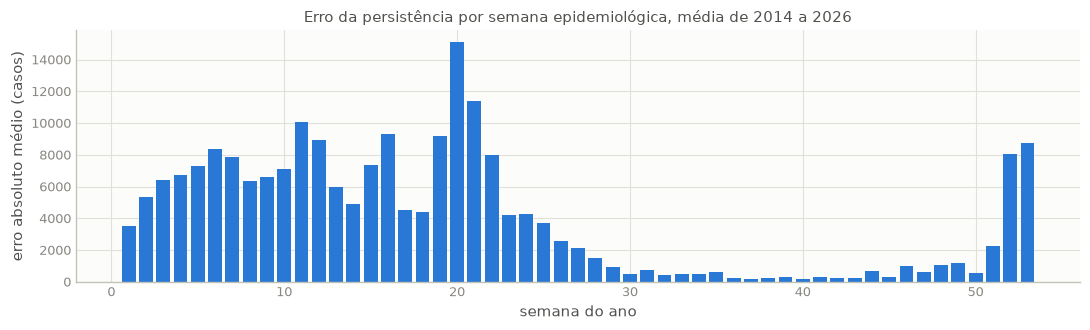

as cinco semanas de maior erro:
shape: (5, 2)
┌────────┬──────────────┐
│ semana ┆ mae          │
│ ---    ┆ ---          │
│ i8     ┆ f64          │
╞════════╪══════════════╡
│ 20     ┆ 15087.0      │
│ 21     ┆ 11389.090909 │
│ 11     ┆ 10054.545455 │
│ 16     ┆ 9279.545455  │
│ 19     ┆ 9154.454545  │
└────────┴──────────────┘


In [18]:
if REAL:
    por_semana = (
        run.predictions.filter(pl.col("baseline") == "persistence")
        .with_columns(
            pl.col("ew").dt.week().alias("semana"),
            (pl.col("y_true") - pl.col("y_pred")).abs().alias("erro"),
        )
        .group_by("semana")
        .agg(pl.col("erro").mean().alias("mae"))
        .sort("semana")
    )

    fig, ax = plt.subplots(figsize=(11, 3.4))
    ax.bar(por_semana["semana"].to_list(), por_semana["mae"].to_list(),
           color=PALETTE["series"][0], width=0.8)
    style_axes(
        ax,
        title="Erro da persistência por semana epidemiológica, média de 2014 a 2026",
        xlabel="semana do ano",
        ylabel="erro absoluto médio (casos)",
    )
    ax.set_ylim(bottom=0)
    plt.tight_layout()
    plt.show()

    print("as cinco semanas de maior erro:")
    print(por_semana.sort("mae", descending=True).head(5))


As cinco piores semanas do ano são as semanas 20, 21, 11, 16 e 19 — maio, fim de maio,
março. São as semanas em que a curva sobe.

A persistência não erra por acaso: ela erra porque copia o presente dentro de um futuro
que já mudou. No vale, o presente e o futuro são o mesmo número e o erro é pequeno. Na
subida, uma semana de diferença vale milhares de casos.

Esse é o espaço onde a notícia teria que ajudar, e é o que a próxima fatia vai testar.
Se a cobertura de dengue cresce antes dos casos subirem — que é a hipótese de
[`notes/01-lexico-regras.md`](../notes/01-lexico-regras.md) —, ela deveria reduzir
exatamente essas semanas. E o desenho que mede isso já existe: é o mesmo `evaluate`,
com uma coluna a mais de covariável.


## 9. O que este notebook encontrou

Os números abaixo são da execução que gerou este arquivo.

**A régua existe, e ela é dura.** Repetir a última semana observada erra 4.047 casos
por semana contra uma média de 30.046 casos nas semanas avaliadas. O erro é de 13% do
nível médio — um patamar que um modelo de notícia precisa superar antes de qualquer
coisa ser dita sobre representação.

**O ingênuo sazonal é o adversário errado.** Ele erra 30.714, sete vezes e meia mais, e
o motivo é estrutural: a série pula de patamar entre anos, então copiar o ano anterior
erra por um fator, não por uma margem. Reportar vitória contra ele seria escolher o
adversário mais fraco.

**As três métricas discordam sobre a pior semana.** O MAE aponta 19 de maio de 2024, o
auge da epidemia recorde, errado por 84.739 casos. O MAPE aponta a última semana do
painel, errada por 4.647 — dezoito vezes menos. Não é defeito de nenhuma das duas: é a
ponderação que cada uma aplica, e é o motivo de as três entrarem juntas na tabela.

**O erro tem endereço.** A persistência quebra nas semanas 20, 21, 11, 16 e 19 — a
subida da epidemia. É onde a notícia pode acrescentar informação, e é onde a próxima
fatia vai olhar.

**O resultado não é artefato de um ano.** Tirando 2024 inteiro, o erro da persistência
cai para 2.614 e o do sazonal para 24.105: a distância sobrevive.

**Aterramento.** O desenho que produz essa leitura é o de
[00-protocolo-comparacao.md](../notes/00-protocolo-comparacao.md) §Ablações obrigatórias.
A leitura de que a notícia tem efeito marginal tem medição publicada em McGough et al.
(2017), e a de que a notícia pode ajudar tem medição publicada em Ghosh et al. (2017),
[04_ghosh_2017_temporal_topic_modeling_assess.pdf](../articles/topicos/04_ghosh_2017_temporal_topic_modeling_assess.pdf),
que encontram o menor erro do conjunto em 8 de 10 combinações de país e doença ao somar
tendências de tópico a um modelo autorregressivo. As duas medições apontam para lados
opostos, e é por isso que a comparação precisa ser feita aqui.


## 10. O que este notebook não prova

**1. Não é o resultado do protocolo 00.** Falta o modelo "sem texto" — o mesmo desenho
com casos defasados, busca do Google e clima. É ele que a notícia tem que bater, e ele
não existe ainda. Os ingênuos medidos aqui são o piso, não a régua final.

**2. Não há métrica probabilística.** O protocolo 00 pede WIS/CRPS (a métrica de
intervalo de previsão, que pontua a distribuição inteira) e cobertura. Os dois palpites
emitem um número por semana e não reivindicam incerteza nenhuma, então calcular aquelas
métricas agora seria inventar uma distribuição que ninguém produziu. Elas entram com o
primeiro modelo que emita intervalo.

**3. O horizonte é de uma semana.** O protocolo deixou o horizonte aberto entre uma e
quatro semanas, e a escolha importa: McGough et al. (2017) medem que o melhor modelo
muda conforme o horizonte — com informação autorregressiva o ganho está em uma semana,
e sem ela em duas e três. Uma semana é onde o ingênuo é mais duro de bater, então é o
lugar honesto para começar, e não o único lugar a medir.

**4. O nível do alvo é a contagem bruta.** Nenhuma transformação logarítmica foi
aplicada. Isso é decisão de modelo e pertence ao modelo, não à régua; mas significa que
a escala do erro acompanha a escala da epidemia, e que os anos de epidemia grande pesam
mais na média.

**5. Sem intervalo de confiança.** Não há bootstrap em blocos sobre o ΔMAE, então as
diferenças entre palpites são lidas pelo tamanho, não por um teste. A diferença de 7,6×
não precisa de teste para ser lida; diferenças pequenas entre braços vão precisar.

**6. A geografia é o Brasil.** Notícia é nacional e o alvo aqui é nacional, então a
comparação não tem descompasso espacial a explicar. A leitura por unidade da federação
é onde a comparação fica interessante, e é onde a esparsidade morde: 4,5 artigos por
semana nacionalmente viram quase nada por UF.

**7. Não há família de referências de previsão neste projeto.** As fichas citadas vêm
das famílias de embeddings e de tópicos, e nenhuma delas trata do desenho de avaliação
como assunto. A disciplina de medir antes de modelar está apoiada no protocolo deste
projeto e em dois resultados empíricos, não em literatura metodológica lida. Montar essa
família é trabalho pendente e declarado.


## 11. Como reproduzir

Este notebook chama o mesmo pacote que a linha de comando:

```bash
uv run arboili transform sinan              # CSVs anuais → tabela de casos  (~11 s)
uv run python -m src.forecast --out data/forecast
```

A segunda linha imprime a mesma tabela da seção 7 e escreve três arquivos em
`data/forecast/` (diretório ignorado pelo git: o que se versiona é o comando, não a tabela
que ele imprime).

As previsões são gravadas por semana, e não só o resumo, por um motivo prático: sem elas
não há como rastrear uma média ruim até as semanas que a causaram, e um pico perdido por
muito é um achado diferente de um erro espalhado.

O terceiro arquivo é o registro da rodada — a janela do painel, o horizonte, quantas
semanas de histórico antes da primeira previsão, de quanto em quanto tempo as origens
andaram, e o comando inteiro. Ele existe porque o resumo sozinho não se defende: lido seis
meses depois, ele não diz se o histórico foram 104 ou 200 semanas, e a diferença entre os
dois não é pequena. O registro não guarda data nem hora, então duas rodadas do mesmo
comando escrevem bytes iguais — e um registro que difere significa que um ajuste diferiu.

### Onde cada decisão está escrita

| Decisão | Onde está escrita |
|---|---|
| A ordem de trabalho (ingênuos antes de qualquer braço) | [`notes/00-protocolo-comparacao.md`](../notes/00-protocolo-comparacao.md) §Ablações obrigatórias |
| A definição do alvo | [`src/pipeline/sinan/cases.py`](../src/pipeline/sinan/cases.py) |
| Calendário sem buraco e a recusa | [`src/forecast/panel.py`](../src/forecast/panel.py) |
| A regra da origem móvel | [`src/forecast/splits.py`](../src/forecast/splits.py) |
| Os dois palpites | [`src/forecast/baselines.py`](../src/forecast/baselines.py) |
| As métricas e o denominador do MAPE | [`src/forecast/metrics.py`](../src/forecast/metrics.py) |
| Constantes e janelas em vigor | [`src/forecast/spec.py`](../src/forecast/spec.py) |
| O registro que acompanha cada resultado | [`src/forecast/record.py`](../src/forecast/record.py) |
| Números, ressalvas e o comando | [`src/forecast/README.md`](../src/forecast/README.md) |
| A hipótese sobre a notícia | [`notes/01-lexico-regras.md`](../notes/01-lexico-regras.md) |


## Resumo executivo

Este notebook constrói a régua da dissertação. Ele entrega a série-alvo em um único
lugar, a divisão temporal que nenhum modelo pode furar, os dois palpites ingênuos e as
três métricas pontuais.

O que a execução encontrou: prever dengue no Brasil uma semana à frente repetindo a
última semana observada erra **4.047 casos por semana** entre 2014 e 2026, contra uma
média de 30.046 casos nas semanas avaliadas — 13% do nível médio. O palpite sazonal — repetir a mesma semana do ano
anterior — erra 30.714, sete vezes e meia mais, porque a série pula de patamar entre
anos e copiar o ano anterior erra por um fator. A régua honesta é a persistência.

O erro da persistência tem endereço: ele se concentra nas semanas 11 a 21, a subida da
epidemia. Um método que só empata no vale e ganha na subida já seria útil, e é
exatamente o que a próxima fatia mede.

O que este notebook **não** entrega é o número do protocolo 00. Falta o modelo "sem
texto" — casos defasados com busca do Google e clima —, que é a barra contra a qual as
três representações de notícia serão comparadas. Os ingênuos medidos aqui são o piso
dessa barra.
